# 02 Análise exploratória (EDA)

EDA é a sigla de *Exploratory Data Analysis*, ou análise exploratória de dados. É a fase de conhecer o terreno antes dos testes: contar, calcular porcentagens, montar tabelas e gráficos e procurar padrões e problemas. **Nada aqui é resultado final:** as estimativas com margem de erro e os testes saem no notebook 03.

- **Entra:** `data/processed/dados_harmonizados.csv`, gerado pelo notebook 01 (uma linha por pessoa, com os dados da casa dela). Só entram os usuários de Internet de 16 anos ou mais, como nas tabelas oficiais da CETIC (seção 2).
- **Sai:** em `outputs/`, a tabela `tabelao_eda.csv` e os gráficos `gap_renda_pct_com_peso.png` e `gap_renda_pct_sem_peso.png`

**Como ler:** cada seção começa com um texto explicando o porquê, e cada célula de código tem comentários (as linhas que começam com `#`) explicando o que cada linha faz. Rodar sempre com **Restart + Run All**, de cima pra baixo.

**Roteiro**
1. Preparar o ambiente
2. Carregar os dados e escolher o universo
3. Funções e dicionários do notebook
4. Quem responde o G2
5. Contagem por área e ano
6. O peso muda o resultado
7. Um exemplo: a renda em saúde e impostos (2024)
8. O n efetivo
9. As quatro dimensões de uma vez
10. O tabelão
11. Testes de integridade
12. Grupos frágeis
13. Gráfico: o gap da renda
14. Salvar
15. Resumo dos achados

## 1. Preparar o ambiente

- `pandas` trabalha com tabelas. Uma tabela inteira é um **DataFrame** e uma coluna sozinha é uma **Series**.
- `matplotlib` desenha os gráficos, e o `seaborn` usa ele por baixo pra fazer gráficos estatísticos com pouco código.
- `os` monta caminhos de arquivo.
- A função `encontrar_raiz_projeto` é a mesma do notebook 01: ela sobe pasta por pasta até achar `src/harmonizacao.py`, pra todos os caminhos funcionarem não importa de onde o VS Code rode o notebook.

In [1]:
# Bibliotecas
import os                          # monta caminhos de arquivo (pastas e nomes)
import pandas as pd                # tabelas (DataFrame) e colunas (Series)
import matplotlib.pyplot as plt    # desenha os gráficos (o seaborn usa ele por baixo)
import seaborn as sns              # gráficos estatísticos com pouco código


def encontrar_raiz_projeto(pasta_atual):
    # Sobe de pasta em pasta até achar a que tem src/harmonizacao.py
    pasta = os.path.abspath(pasta_atual)          # caminho completo da pasta onde o notebook está rodando
    while True:                                   # repete até achar (return) ou desistir (raise)
        if os.path.exists(os.path.join(pasta, 'src', 'harmonizacao.py')):
            return pasta                          # achou: essa é a raiz do projeto
        pasta_pai = os.path.dirname(pasta)        # a pasta "de cima"
        if pasta_pai == pasta:                    # não dá mais pra subir: chegou na raiz do disco
            raise FileNotFoundError('Não achei src/harmonizacao.py subindo a partir de ' + pasta_atual)
        pasta = pasta_pai                         # continua procurando uma pasta acima


raiz_projeto = encontrar_raiz_projeto(os.getcwd())   # os.getcwd() = pasta atual

pd.set_option('display.max_columns', None)   # mostra todas as colunas nas tabelas
sns.set_theme(style='whitegrid')             # estilo dos gráficos: fundo branco com uma grade clarinha

## 2. Carregar os dados e escolher o universo

- O notebook usa só o `dados_harmonizados.csv`: uma linha por pessoa entrevistada, com os dados da casa dela (renda, região etc.) e o `peso_amostral_individuo`, que é o peso certo pra qualquer conta com G1 e G2.
- O `assert` confere se o arquivo é o que o notebook 01 gerou (66.976 pessoas e 33 colunas). Se der erro, é porque o arquivo está desatualizado: rode o notebook 01 de novo.

In [2]:
# Arquivo principal: uma linha por pessoa, com os dados da casa dela (sai do notebook 01)
dados = pd.read_csv(os.path.join(raiz_projeto, 'data', 'processed', 'dados_harmonizados.csv'))

# Confere se é o arquivo certo: 66.976 pessoas e 33 colunas, como no notebook 01
assert dados.shape == (66976, 33), f'Tamanho inesperado: {dados.shape}. Rode o notebook 01 de novo.'

print(dados.shape)
dados.head()

(66976, 33)


,chave_domicilio,ID_MORADOR,ano,idade,sexo,raca,escolaridade,g1_agreg,transacoes_financeiras,usuario_internet,peso_amostral_individuo,G1_A,G1_B,G1_C,G1_D,G1_E,G1_F,G1_G,G2_A,G2_B,G2_C,G2_D,G2_E,G2_F,G2_G,G1_H,G2_H,renda_familiar,classe_economica,regiao,area_urbano_rural,velocidade_conexao,valor_conexao
0,2,1,2023,36,2,3.0,2,1,0.0,1,344.582890,0.0,0.0,0.0,0.0,1.0,0.0,0.0,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,1.0,4,4,1,NaN,9.0
1,3,2,2023,53,2,1.0,4,1,0.0,1,1765.454757,0.0,1.0,0.0,1.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,4.0,2,4,1,NaN,9.0
2,4,1,2023,71,2,2.0,2,0,0.0,1,474.963986,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,4,4,1,baixa,7.0
3,5,3,2023,37,2,1.0,3,0,0.0,1,599.592121,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,3,4,1,NaN,7.0
4,6,1,2023,30,1,3.0,3,0,1.0,1,416.368061,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,4,4,1,media,8.0


**O universo: usuários de Internet de 16 anos ou mais**

- As tabelas oficiais da CETIC sobre o módulo G contam só os **usuários de Internet de 16 anos ou mais**: quem tem 16 anos ou mais e disse, na pergunta C3, que usou a internet nos últimos 3 meses. No arquivo, isso é a coluna `usuario_internet` (1 = está no universo), que o notebook 01 trouxe da `F_C3_IDADE` da CETIC.
- Só que o questionário aplica o módulo G a um grupo um pouco maior: quem tem 16 anos ou mais e usou a internet nos últimos 3 meses pela C3 **ou** pela J3 ("usou a Internet pelo telefone celular nos últimos três meses?"). Umas mil pessoas por ano disseram "não" na C3 e "sim" na J3. Elas responderam o G1 e o G2, mas ficam fora das tabelas oficiais.
- Com essas pessoas, os nossos % não batiam com os da CETIC. Sem elas, batem exatamente, nos 3 anos (conferido com as planilhas oficiais, que estão em `docs/fontes_cetic/tabelas/`). Por isso o universo da análise é o mesmo da CETIC (decisão de 12/10, no caderno de bordo).
- A célula mostra quantas pessoas estão dentro (1) e fora (0) do universo em cada ano e quantas de fora responderam o G1. Depois disso, `dados` passa a ter só o universo: **todas as contas daqui pra baixo são entre usuários de Internet de 16 anos ou mais.**

In [3]:
# Quantas pessoas estão no universo (1) e fora dele (0), por ano
print(pd.crosstab(dados['ano'], dados['usuario_internet']), '\n')

# Quantas pessoas de FORA do universo responderam o G1 de pelo menos uma área
colunas_g1 = [f'G1_{letra}' for letra in 'ABCDEFGH']
respondeu_g1 = dados[colunas_g1].notna().any(axis=1)      # axis=1: olha as colunas de cada linha; True se respondeu alguma
fora_do_universo = dados['usuario_internet'] == 0
print('Fora do universo, mas responderam o G1:')
print(dados[fora_do_universo & respondeu_g1].groupby('ano').size(), '\n')

# Daqui pra frente, só o universo da CETIC: usuários de Internet de 16 anos ou mais
dados = dados[dados['usuario_internet'] == 1]
assert len(dados) == 13859 + 14686 + 16891, 'O universo não tem o tamanho esperado'
print('Pessoas no universo:', len(dados))

usuario_internet     0      1
ano                          
2023              7412  13859
2024              6484  14686
2025              7644  16891 

Fora do universo, mas responderam o G1:
ano
2023    1133
2024     967
2025    1088
dtype: int64 

Pessoas no universo: 45436


## 3. Funções e dicionários do notebook

As funções ficam aqui em cima porque o **Restart + Run All** roda o notebook de cima pra baixo: uma função tem que existir antes do código que usa ela.

- **`porcentagem_com_peso(resposta, peso)`:** o % de pessoas que responderam 1, contando cada pessoa pelo seu peso, ou seja, quantos brasileiros ela representa. A conta é 100 × (soma dos pesos de quem respondeu 1) ÷ (soma dos pesos de todo mundo que respondeu). O NaN fica de fora.
- **`n_efetivo(peso)`:** quantas pessoas um grupo **vale de verdade**, considerando os pesos (fórmula de Kish): (soma dos pesos)² ÷ (soma de cada peso ao quadrado). Se todo mundo tem o mesmo peso, dá o próprio n. Se poucas pessoas têm pesos gigantes, o resultado depende quase só delas, e o n efetivo fica bem menor que o n. A seção 8 mostra um exemplo real.
- **`tabela_por_grupo(base, coluna_area, coluna_grupo, nomes)`:** monta a tabela de uma área (G2), separando por um grupo (renda, raça, escolaridade ou região). É um loop com "buracos" nos lugares que mudam: você escolhe o ano (`base`), a área, o grupo e o dicionário de nomes, e ela devolve uma linha por categoria com `n`, `resolveram`, `pct_sem_peso`, `pct_com_peso` e `n_efetivo`.
- **`gap_da_renda(tabelao, medida)`:** o gap da renda (faixa "mais de 10 SM" menos faixa "até 1 SM") em cada ano e área. É usada no gráfico da seção 13.

Os **dicionários** traduzem os códigos em nomes. Os rótulos vêm dos dicionários oficiais da CETIC (`docs/fontes_cetic/dicionarios/`). O `grupos` junta cada coluna com o seu dicionário, pra nunca acontecer de usar os nomes da renda na coluna de raça.

In [4]:
def porcentagem_com_peso(resposta, peso):
    # % de 1 numa coluna 0/1, usando o peso de cada pessoa e ignorando os vazios (NaN)
    tem_resposta = resposta.notna()          # True pra quem respondeu
    y = resposta[tem_resposta]               # as respostas (0 ou 1)
    w = peso[tem_resposta]                   # o peso de cada uma dessas pessoas
    return 100 * (w * y).sum() / w.sum()     # pesos de quem respondeu 1 ÷ pesos de todo mundo


def n_efetivo(peso):
    # Quantas pessoas o grupo "vale" de verdade, considerando os pesos (fórmula de Kish)
    return peso.sum() ** 2 / (peso ** 2).sum()       # ** 2 = ao quadrado


def tabela_por_grupo(base, coluna_area, coluna_grupo, nomes):
    # base:          os dados de um ano (ex.: d24)
    # coluna_area:   a pergunta G2 da área (ex.: 'G2_B')
    # coluna_grupo:  a coluna que separa os grupos (ex.: 'renda_familiar')
    # nomes:         o dicionário que traduz os códigos do grupo (ex.: nomes_renda)
    responderam = base[base[coluna_area].notna()]          # só quem respondeu a pergunta da área

    linhas = []
    for codigo, nome in nomes.items():                     # uma volta pra cada categoria do grupo
        grupo = responderam[responderam[coluna_grupo] == codigo]   # só as pessoas desta categoria
        n = len(grupo)                                     # quantas pessoas tem na categoria
        resolveram = (grupo[coluna_area] == 1).sum()       # quantas resolveram tudo online
        linhas.append({
            'categoria': nome,
            'n': n,
            'resolveram': resolveram,
            'pct_sem_peso': round(100 * resolveram / n, 1),
            'pct_com_peso': round(porcentagem_com_peso(grupo[coluna_area], grupo['peso_amostral_individuo']), 1),
            'n_efetivo': round(n_efetivo(grupo['peso_amostral_individuo'])),
        })

    return pd.DataFrame(linhas)                            # devolve a tabela pronta pra quem chamou


def gap_da_renda(tabelao, medida):
    # Gap da renda (mais de 10 SM menos até 1 SM) em cada ano e área
    # medida: 'pct_com_peso' ou 'pct_sem_peso'
    renda = tabelao[(tabelao['dimensao'] == 'renda_familiar') & (tabelao['area'] != 'justiça')]   # justiça só existe em 2025
    pontas = renda.pivot_table(index=['ano', 'area'], columns='categoria', values=medida)          # cada faixa de renda vira uma coluna
    pontas['gap'] = pontas['mais de 10 SM'] - pontas['até 1 SM']      # a faixa mais rica menos a mais pobre
    pontas = pontas.reset_index()                  # ano e area voltam a ser colunas normais
    pontas.columns.name = None                     # tira o nome "categoria" que o pivot deixou no cabeçalho
    pontas['ano'] = pontas['ano'].astype(str)      # ano vira texto, pra cada ano ganhar uma cor no gráfico
    return pontas[['ano', 'area', 'até 1 SM', 'mais de 10 SM', 'gap']]

In [5]:
# Dicionários: traduzem códigos em nomes (rótulos dos dicionários oficiais da CETIC)
nomes_areas = {'A': 'documentos', 'B': 'saúde', 'C': 'educação', 'D': 'trabalho',
               'E': 'impostos', 'F': 'polícia', 'G': 'transporte', 'H': 'justiça'}

# Renda da família inteira somada, em salários mínimos (SM). O 7 é "não tem renda"
nomes_renda = {1: 'até 1 SM', 2: '1 a 2 SM', 3: '2 a 3 SM', 4: '3 a 5 SM',
               5: '5 a 10 SM', 6: 'mais de 10 SM', 7: 'não tem renda'}
nomes_raca = {1: 'branca', 2: 'preta', 3: 'parda', 4: 'amarela', 5: 'indígena'}
nomes_escolaridade = {1: 'analfabeto/infantil', 2: 'fundamental', 3: 'médio', 4: 'superior'}
nomes_regiao = {1: 'Sudeste', 2: 'Nordeste', 3: 'Sul', 4: 'Norte', 5: 'Centro-Oeste'}

# Cada coluna de grupo anda junto com o seu dicionário de nomes
grupos = {
    'renda_familiar': nomes_renda,
    'raca': nomes_raca,
    'escolaridade': nomes_escolaridade,
    'regiao': nomes_regiao,
}

In [6]:
# Testes das funções com números inventados, em que a gente já sabe a resposta
resposta_teste = pd.Series([1, 0, 0, 1])

assert porcentagem_com_peso(resposta_teste, pd.Series([1, 1, 1, 1])) == 50                    # pesos iguais: 2 de 4 = 50%
assert round(porcentagem_com_peso(resposta_teste, pd.Series([3, 1, 1, 1])), 1) == 66.7        # o peso 3 conta 3 vezes: 4 de 6
assert porcentagem_com_peso(pd.Series([1, 0, None]), pd.Series([1, 1, 1])) == 50             # o NaN fica de fora
assert n_efetivo(pd.Series([1, 1, 1, 1])) == 4                                                # pesos iguais: n efetivo = n
assert round(n_efetivo(pd.Series([97, 1, 1, 1])), 2) == 1.06                                  # um peso gigante: vale ~1 pessoa

print('Funções conferidas')

Funções conferidas


## 4. Quem responde o G2

- O **G1** pergunta se a pessoa **tentou** usar a internet pra um serviço público de cada área (1 = sim, 0 = não). Depois do filtro da seção 2, ele vale pra todo mundo que sobrou: os usuários de Internet de 16 anos ou mais.
- O **G2** pergunta se ela **resolveu tudo pela internet**, sem ir até um posto (1 = sim, 0 = não). Pelo questionário, ele só é feito pra quem tentou (G1 = 1). Quem não foi perguntado fica com NaN.
- Por isso, **todo % do G2 é "entre quem tentou"**. Algumas pessoas tentaram mas ficaram com G2 em NaN: são os "não sabe" e "não respondeu" do G2 (de 3 a 26 pessoas por área e ano).
- A primeira célula mostra isso pra saúde. A segunda confere o filtro em todas as áreas e anos.

In [7]:
# Saúde (área B): quantos resolveram (1), quantos não (0) e quantos não foram perguntados, por ano
pd.crosstab(dados['ano'], dados['G2_B'].fillna('não perguntado'))

G2_B,0.0,1.0,não perguntado
ano,,,
2023,3816,883,9160
2024,2915,977,10794
2025,4562,1150,11179


In [8]:
# Confere o filtro do questionário em todas as áreas: ninguém respondeu o G2 sem ter dito que tentou (G1 = 1)
for letra in nomes_areas:
    g1 = dados[f'G1_{letra}']
    g2 = dados[f'G2_{letra}']
    respondeu_sem_tentar = (g2.notna() & (g1 != 1)).sum()     # respondeu o G2, mas o G1 não é 1
    assert respondeu_sem_tentar == 0, f'G2_{letra}: {respondeu_sem_tentar} pessoas responderam sem ter tentado'

print('Filtro conferido: o G2 só aparece pra quem tentou (G1 = 1)')

Filtro conferido: o G2 só aparece pra quem tentou (G1 = 1)


## 5. Contagem por área e ano

Uma linha por área e ano, com:

- **`responderam_G1`** e **`tentaram`**: quantas pessoas responderam o G1 e quantas disseram que tentaram (G1 = 1)
- **`responderam_G2`** e **`resolveram`**: quantas responderam o G2 e quantas resolveram tudo online (G2 = 1)
- **`pct_sem_peso`**: resolveram ÷ responderam_G2, contando cada pessoa uma vez
- **`pct_com_peso`**: o mesmo %, mas com o peso de cada pessoa. É esse que vale pro Brasil.
- **`n_efetivo`**: quantas pessoas as respostas do G2 valem de verdade, considerando os pesos
- **`diferenca`**: com peso menos sem peso, ou seja, quanto o peso mudou o resultado

O que dá pra ver:
- **O peso muda o % em até ~10 p.p.** O maior caso é transporte 2023 (seção 6).
- **O n efetivo é bem menor que o n.** Em saúde 2024, por exemplo, as 3.892 respostas valem só umas 190 pessoas (n efetivo 192), por causa da variação dos pesos.

In [9]:
linhas = []
for ano in [2023, 2024, 2025]:
    d = dados[dados['ano'] == ano]                     # os dados de um ano

    for letra, nome_area in nomes_areas.items():
        if letra == 'H' and ano != 2025:               # justiça só existe em 2025
            continue

        g1 = d[f'G1_{letra}']                          # tentou? (0/1)
        g2 = d[f'G2_{letra}']                          # resolveu tudo online? (0/1, NaN = não perguntado)
        peso_g2 = d.loc[g2.notna(), 'peso_amostral_individuo']    # o peso só de quem respondeu o G2

        linhas.append({
            'ano': ano,
            'area': nome_area,
            'responderam_G1': g1.notna().sum(),
            'tentaram': (g1 == 1).sum(),
            'responderam_G2': g2.notna().sum(),
            'resolveram': (g2 == 1).sum(),
            'pct_sem_peso': round(100 * (g2 == 1).sum() / g2.notna().sum(), 1),
            'pct_com_peso': round(porcentagem_com_peso(g2, d['peso_amostral_individuo']), 1),
            'n_efetivo': round(n_efetivo(peso_g2)),
        })

contagem = pd.DataFrame(linhas)
contagem['diferenca'] = (contagem['pct_com_peso'] - contagem['pct_sem_peso']).round(1)   # quanto o peso mudou o %
contagem

,ano,area,responderam_G1,tentaram,responderam_G2,resolveram,pct_sem_peso,pct_com_peso,n_efetivo,diferenca
0,2023,documentos,13827,3645,3629,1039,28.6,35.2,210,6.6
1,2023,saúde,13829,4722,4699,883,18.8,21.8,396,3.0
2,2023,educação,13826,2916,2908,946,32.5,34.0,148,1.5
3,2023,trabalho,13821,3939,3928,1163,29.6,34.4,225,4.8
4,2023,impostos,13818,3467,3453,1682,48.7,55.4,220,6.7
5,2023,polícia,13829,1394,1387,573,41.3,45.3,147,4.0
6,2023,transporte,13830,1563,1551,508,32.8,43.2,69,10.4
7,2024,documentos,14658,3371,3355,1071,31.9,31.4,185,-0.5
8,2024,saúde,14660,3906,3892,977,25.1,25.8,192,0.7
9,2024,educação,14669,2389,2383,870,36.5,36.4,100,-0.1


## 6. O peso muda o resultado

Transporte 2023 tem a maior `diferenca` da tabela acima (32,8% sem peso e 43,2% com peso). A célula abaixo olha as pessoas mais pesadas entre quem respondeu.

- `sort_values(..., ascending=False)` ordena do maior peso pro menor, e `nlargest(5)` pega os 5 maiores valores.
- O peso diz **quantos brasileiros cada entrevistado representa**. Quando uma pessoa sozinha carrega uma fatia grande do peso, o % depende muito da resposta dela.
- A última conta tira as 5 pessoas mais pesadas **só pra medir o tamanho do efeito**. Na análise de verdade ninguém é tirado: elas representam gente real. O certo é mostrar a margem de erro, que sai no notebook 03.

In [10]:
# Transporte (área G) em 2023: só quem respondeu o G2
transporte_2023 = dados[(dados['ano'] == 2023) & (dados['G2_G'].notna())]
pesos = transporte_2023['peso_amostral_individuo']

# As 5 pessoas mais pesadas e o que elas responderam
mais_pesados = transporte_2023.sort_values('peso_amostral_individuo', ascending=False)
print(mais_pesados[['G2_G', 'peso_amostral_individuo']].head(5).round().astype(int), '\n')   # arredonda pra ler melhor

print('Pessoas que responderam:', len(transporte_2023))
print('Parte do peso na pessoa mais pesada:', round(100 * pesos.max() / pesos.sum(), 1), '%')
print('Parte do peso nas 5 mais pesadas:', round(100 * pesos.nlargest(5).sum() / pesos.sum(), 1), '%')

# Só pra medir o efeito (ninguém é tirado da análise de verdade)
sem_os_5 = mais_pesados.iloc[5:]          # todo mundo menos as 5 primeiras da lista ordenada
print('% com peso, todo mundo:', round(porcentagem_com_peso(transporte_2023['G2_G'], pesos), 1))
print('% com peso, sem as 5 mais pesadas:', round(porcentagem_com_peso(sem_os_5['G2_G'], sem_os_5['peso_amostral_individuo']), 1))

       G2_G  peso_amostral_individuo
15530     1                  1879332
15572     0                   665641
15526     1                   493244
15472     0                   412356
15708     1                   407767 

Pessoas que responderam: 1551
Parte do peso na pessoa mais pesada: 9.5 %
Parte do peso nas 5 mais pesadas: 19.5 %
% com peso, todo mundo: 43.2
% com peso, sem as 5 mais pesadas: 36.1


## 7. Um exemplo: a renda em saúde e impostos (2024)

- A renda é a **da família inteira somada**, em salários mínimos (SM), em 6 faixas, mais o código 7 ("não tem renda").
- Quem não soube ou não quis dizer a renda virou NaN no notebook 01 e fica fora das tabelas por renda. A primeira célula mostra quantas pessoas são.
- As duas tabelas usam a função `tabela_por_grupo`.

O que dá pra ver:
- **Impostos tem uma escada clara.** Quanto maior a renda, mais gente resolve, nas duas colunas (com peso: 38,3 → 47,7 → 53,2 → 60,6 → 66,7 → 81,4). O gap das pontas (mais de 10 SM menos até 1 SM) é de 43,1 p.p. com peso.
- **Saúde tem escada sem peso, mas zigue-zague com peso.** O gap com peso é de só 13,0 p.p.
- **O "não tem renda" de saúde despenca com peso:** de 19,6% pra 5,9%. A seção 8 explica por quê.

In [11]:
d24 = dados[dados['ano'] == 2024]                 # só 2024
saude_2024 = d24[d24['G2_B'].notna()]             # quem respondeu a pergunta de saúde

# Quantas pessoas em cada código de renda (NaN = não soube ou não quis dizer a renda)
saude_2024['renda_familiar'].value_counts(dropna=False).sort_index()

renda_familiar
1.0    1141
2.0    1084
3.0     745
4.0     441
5.0     204
6.0      56
7.0      51
NaN     170
Name: count, dtype: int64

In [12]:
# Saúde (G2_B) em 2024, por faixa de renda
saude_renda = tabela_por_grupo(d24, 'G2_B', 'renda_familiar', nomes_renda)
saude_renda

,categoria,n,resolveram,pct_sem_peso,pct_com_peso,n_efetivo
0,até 1 SM,1141,227,19.9,24.8,237
1,1 a 2 SM,1084,263,24.3,18.3,69
2,2 a 3 SM,745,204,27.4,34.1,38
3,3 a 5 SM,441,148,33.6,24.7,42
4,5 a 10 SM,204,59,28.9,34.1,25
5,mais de 10 SM,56,18,32.1,37.8,15
6,não tem renda,51,10,19.6,5.9,3


In [13]:
# Impostos (G2_E) em 2024, por faixa de renda
impostos_renda = tabela_por_grupo(d24, 'G2_E', 'renda_familiar', nomes_renda)
impostos_renda

,categoria,n,resolveram,pct_sem_peso,pct_com_peso,n_efetivo
0,até 1 SM,392,127,32.4,38.3,103
1,1 a 2 SM,641,280,43.7,47.7,80
2,2 a 3 SM,638,344,53.9,53.2,45
3,3 a 5 SM,558,338,60.6,60.6,54
4,5 a 10 SM,364,237,65.1,66.7,48
5,mais de 10 SM,116,85,73.3,81.4,14
6,não tem renda,14,8,57.1,57.9,5


## 8. O n efetivo

Por que o "não tem renda" de saúde 2024 caiu de 19,6% pra 5,9% quando entrou o peso?

- O grupo tem 51 pessoas, mas **uma só carrega 58% do peso do grupo**, e ela respondeu 0 (não resolveu). As outras 4 mais pesadas também responderam 0.
- É como uma votação de 51 pessoas em que uma tem 58% dos votos: o que ela escolher, ganha.
- O **n efetivo** mede isso: esse grupo de 51 pessoas **vale só umas 3**.

Por que isso importa: a margem de erro depende do n efetivo, e não do n. Um grupo que vale 3 pessoas tem uma margem enorme, como uma pesquisa que entrevistou só 3. **Regra prática: n efetivo pequeno quer dizer "não confie nesse % sozinho".** No notebook 03, a margem de erro sai das 200 réplicas, que já levam tudo isso em conta.

In [14]:
# "Não tem renda" (código 7) em saúde 2024: as pessoas mais pesadas e o que elas responderam
sem_renda = saude_2024[saude_2024['renda_familiar'] == 7]
mais_pesados = sem_renda.sort_values('peso_amostral_individuo', ascending=False)
print(mais_pesados[['G2_B', 'peso_amostral_individuo']].head(5).round().astype(int), '\n')   # arredonda pra ler melhor

pesos = sem_renda['peso_amostral_individuo']
print('Pessoas no grupo:', len(sem_renda))
print('Parte do peso na pessoa mais pesada:', round(100 * pesos.max() / pesos.sum(), 1), '%')
print('n efetivo:', round(n_efetivo(pesos), 1))

       G2_B  peso_amostral_individuo
36163     0                   264638
36737     0                    41228
36424     0                    26283
32766     0                    16888
36842     0                    14152 

Pessoas no grupo: 51
Parte do peso na pessoa mais pesada: 57.6 %
n efetivo: 2.9


## 9. As quatro dimensões de uma vez

- O loop passa pelo dicionário `grupos` e chama a função uma vez pra cada dimensão (renda, raça, escolaridade e região), aqui pra impostos 2024.
- `tabela['dimensao'] = coluna_grupo` cria uma coluna dizendo de qual grupo veio cada linha, e o `pd.concat` empilha as 4 tabelas numa só.

Depois vem a pergunta do projeto, em miniatura: **qual dimensão tem a maior diferença?** Dentro de cada dimensão, a conta é a maior % menos a menor % com peso. O `groupby('dimensao')` separa as linhas em pilhas, uma por dimensão, e o `agg(['max', 'min'])` pega a maior e a menor de cada pilha. A conta é feita com duas "réguas" pra ignorar grupos frágeis: n efetivo de 10 pra cima e de 20 pra cima.

O que dá pra ver:
- **A resposta muda com a régua.** Com 10 a renda fica em 1º; com 20, a região. Se a régua fosse escolhida depois de ver o resultado, dava pra escolher a resposta. Por isso a regra pros grupos pequenos tinha que ser decidida **antes** dos testes, como foi feito com o α = 0,05. Ela foi: é a decisão nº 4 do caderno (12/10).
- **"Maior menos menor" premia grupos frágeis.** Com a régua 10, as pontas da raça eram amarela e preta, justamente os grupos mais frágeis (n efetivo 14 e 11). Grupo frágil balança mais e cai nas pontas por acaso. Por isso a decisão nº 3 (12/10) compara sempre grupos fixos (as pontas da renda e da escolaridade; branca e Sudeste como referência).

In [15]:
tabelas = []
for coluna_grupo, nomes in grupos.items():
    tabela = tabela_por_grupo(d24, 'G2_E', coluna_grupo, nomes)    # impostos 2024, uma dimensão por vez
    tabela['dimensao'] = coluna_grupo                             # anota de qual dimensão veio cada linha
    tabelas.append(tabela)

impostos_2024_todos = pd.concat(tabelas, ignore_index=True)       # empilha as 4 tabelas numa só
impostos_2024_todos

,categoria,n,resolveram,pct_sem_peso,pct_com_peso,n_efetivo,dimensao
0,até 1 SM,392,127,32.4,38.3,103,renda_familiar
1,1 a 2 SM,641,280,43.7,47.7,80,renda_familiar
2,2 a 3 SM,638,344,53.9,53.2,45,renda_familiar
3,3 a 5 SM,558,338,60.6,60.6,54,renda_familiar
4,5 a 10 SM,364,237,65.1,66.7,48,renda_familiar
5,mais de 10 SM,116,85,73.3,81.4,14,renda_familiar
6,não tem renda,14,8,57.1,57.9,5,renda_familiar
7,branca,938,565,60.2,64.5,115,raca
8,preta,385,180,46.8,33.0,11,raca
9,parda,1439,703,48.9,54.7,113,raca


In [16]:
# Qual dimensão tem a maior diferença (maior % menos menor %, com peso)? Com duas réguas diferentes
for corte in [10, 20]:
    confiaveis = impostos_2024_todos[impostos_2024_todos['n_efetivo'] >= corte]     # tira as categorias frágeis
    resumo = confiaveis.groupby('dimensao')['pct_com_peso'].agg(['max', 'min'])    # maior e menor % de cada dimensão
    resumo['diferenca'] = resumo['max'] - resumo['min']
    print(f'Régua: n efetivo >= {corte}')
    print(resumo.sort_values('diferenca', ascending=False).round(1), '\n')

Régua: n efetivo >= 10
                 max   min  diferenca
dimensao                             
renda_familiar  81.4  38.3       43.1
raca            70.0  33.0       37.0
regiao          67.0  34.7       32.3
escolaridade    62.6  39.6       23.0 

Régua: n efetivo >= 20
                 max   min  diferenca
dimensao                             
regiao          67.0  34.7       32.3
renda_familiar  66.7  38.3       28.4
escolaridade    62.6  39.6       23.0
raca            64.5  54.7        9.8 



## 10. O tabelão

Agora a mesma conta pra todos os anos, todas as áreas e todas as dimensões, numa tabela só. São três loops, um dentro do outro: ano, área e dimensão.

- **Tamanho previsto:** 22 combinações de ano e área (7 áreas × 3 anos, mais justiça em 2025) × 21 categorias (7 de renda + 5 de raça + 4 de escolaridade + 5 de região) = **462 linhas**.
- **Colunas:** `ano`, `area`, `dimensao`, `categoria`, `n`, `resolveram`, `pct_sem_peso`, `pct_com_peso` e `n_efetivo`.
- É a base do gráfico da seção 13 e do arquivo `outputs/tabelao_eda.csv`.

In [17]:
tabelas = []
for ano in [2023, 2024, 2025]:
    d = dados[dados['ano'] == ano]                       # os dados de um ano

    for letra, nome_area in nomes_areas.items():
        if letra == 'H' and ano != 2025:                 # justiça só existe em 2025
            continue

        for coluna_grupo, nomes in grupos.items():
            tabela = tabela_por_grupo(d, f'G2_{letra}', coluna_grupo, nomes)
            tabela['ano'] = ano                          # anota de onde veio cada linha
            tabela['area'] = nome_area
            tabela['dimensao'] = coluna_grupo
            tabelas.append(tabela)

tabelao = pd.concat(tabelas, ignore_index=True)

# Põe as colunas numa ordem boa de ler
tabelao = tabelao[['ano', 'area', 'dimensao', 'categoria', 'n', 'resolveram',
                   'pct_sem_peso', 'pct_com_peso', 'n_efetivo']]

print(tabelao.shape)
tabelao.head(21)

(462, 9)


,ano,area,dimensao,categoria,n,resolveram,pct_sem_peso,pct_com_peso,n_efetivo
0,2023,documentos,renda_familiar,até 1 SM,923,187,20.3,18.1,75
1,2023,documentos,renda_familiar,1 a 2 SM,988,264,26.7,41.0,31
2,2023,documentos,renda_familiar,2 a 3 SM,635,207,32.6,49.3,51
3,2023,documentos,renda_familiar,3 a 5 SM,492,174,35.4,29.8,44
4,2023,documentos,renda_familiar,5 a 10 SM,241,96,39.8,31.9,38
5,2023,documentos,renda_familiar,mais de 10 SM,110,45,40.9,36.3,17
6,2023,documentos,renda_familiar,não tem renda,51,8,15.7,21.5,16
7,2023,documentos,raca,branca,987,328,33.2,38.1,55
8,2023,documentos,raca,preta,554,140,25.3,41.4,50
9,2023,documentos,raca,parda,1882,517,27.5,31.5,139


## 11. Testes de integridade

Igual ao notebook 01: antes de usar o tabelão, conferir se ele está certo. Se algum `assert` falhar, o notebook para com erro e diz o que deu errado.

1. **Tamanho:** 462 linhas e 9 colunas, como previsto.
2. **Nenhuma categoria vazia:** n = 0 daria divisão por zero.
3. **O n efetivo nunca passa do n:** pela fórmula, no máximo ele é igual (quando todos os pesos são iguais). Se passar, tem erro na conta.
4. **Ninguém some no caminho:** escolaridade e região não têm NaN, então a soma do n das categorias tem que dar exatamente o `responderam_G2` da contagem (seção 5), em cada área e ano. Renda e raça têm NaN (quem não informou), então a soma delas dá um pouco menos.

In [18]:
# 1) Tamanho previsto: 22 combinações de ano e área × 21 categorias = 462 linhas, 9 colunas
assert tabelao.shape == (462, 9)

# 2) Nenhuma categoria vazia
assert (tabelao['n'] > 0).all()

# 3) O n efetivo nunca passa do n
assert (tabelao['n_efetivo'] <= tabelao['n']).all()

# 4) Escolaridade e região: a soma das categorias = quem respondeu o G2, em cada ano e área
responderam = contagem.set_index(['ano', 'area'])['responderam_G2'].sort_index()
for dimensao in ['escolaridade', 'regiao']:
    soma = tabelao[tabelao['dimensao'] == dimensao].groupby(['ano', 'area'])['n'].sum().sort_index()
    assert soma.tolist() == responderam.tolist(), f'{dimensao}: a soma das categorias não bate com a contagem'

print('Todos os testes passaram')

Todos os testes passaram


## 12. Grupos frágeis

- **Régua de treino:** n efetivo menor que 10. A regra oficial é a decisão nº 4 do caderno (12/10): toda estimativa sai com IC e com aviso quando o CV passa de 30%, e os testes usam categorias fixas.
- Cada categoria aparece no máximo **22 vezes** no tabelão, uma por combinação de ano e área. Então "18" quer dizer frágil em 18 das 22.
- A regra que estava proposta no caderno antes era "tirar do teste se o n ficar abaixo de 50". Ela conta pessoas sem olhar os pesos.

O que dá pra ver:
- Os grupos frágeis são quase sempre analfabeto/infantil, indígena, não tem renda e mais de 10 SM.
- **A regra "n ≥ 50" não basta.** 18 linhas passam nela, mas têm n efetivo menor que 10. No transporte 2023, por exemplo, o "1 a 2 SM" tem 417 pessoas, n efetivo 9, e o % pula de 29,3 pra 49,6 quando entra o peso. Por isso a decisão nº 4 olha a margem de erro e o CV (que saem das réplicas no notebook 03), e não só o n.

In [19]:
# Linhas frágeis: n efetivo menor que 10
frageis = tabelao[tabelao['n_efetivo'] < 10]
print(len(frageis), 'de', len(tabelao), 'linhas têm n efetivo menor que 10')
print(frageis['categoria'].value_counts(), '\n')

# A regra proposta no caderno conta pessoas, sem olhar o peso: n menor que 50
poucos = tabelao[tabelao['n'] < 50]
print(len(poucos), 'de', len(tabelao), 'linhas têm n menor que 50')
print(poucos['categoria'].value_counts())

66 de 462 linhas têm n efetivo menor que 10
categoria
analfabeto/infantil    18
indígena               17
não tem renda          17
mais de 10 SM           7
amarela                 4
preta                   2
1 a 2 SM                1
Name: count, dtype: int64 

55 de 462 linhas têm n menor que 50
categoria
não tem renda          17
analfabeto/infantil    17
indígena                9
mais de 10 SM           6
amarela                 6
Name: count, dtype: int64


In [20]:
# Passa na regra do caderno (n de 50 pra cima), mas é frágil (n efetivo menor que 10)
passa_mas_fragil = tabelao[(tabelao['n'] >= 50) & (tabelao['n_efetivo'] < 10)]     # & = "E": as duas condições
print(len(passa_mas_fragil), 'linhas')
passa_mas_fragil.sort_values('n', ascending=False).head(8)

18 linhas


,ano,area,dimensao,categoria,n,resolveram,pct_sem_peso,pct_com_peso,n_efetivo
127,2023,transporte,renda_familiar,1 a 2 SM,417,122,29.3,49.6,9
281,2024,transporte,raca,preta,202,83,41.1,27.4,6
260,2024,polícia,raca,preta,178,68,38.2,19.3,3
152,2024,documentos,renda_familiar,mais de 10 SM,71,31,43.7,57.3,8
158,2024,documentos,raca,indígena,70,23,32.9,36.1,7
32,2023,saúde,raca,indígena,67,9,13.4,4.4,5
96,2023,impostos,escolaridade,analfabeto/infantil,64,22,34.4,34.8,8
215,2024,trabalho,renda_familiar,mais de 10 SM,59,26,44.1,70.2,7


## 13. Gráfico: o gap da renda

O gap da renda é a faixa mais rica ("mais de 10 SM") menos a mais pobre ("até 1 SM"), em pontos percentuais (p.p.), pra cada área e ano. É um resumo da escada da seção 7 e uma prévia do ranking do projeto. Justiça fica de fora porque só existe em 2025.

- A tabela mostra os dois gaps lado a lado: sem peso e com peso.
- Os gráficos usam a **mesma escala** (`xlim`), pra dar pra comparar um com o outro. As cores são 3 tons do mesmo azul: claro = 2023, escuro = 2025. A linha cinza é o zero: barra pra esquerda quer dizer que a faixa mais pobre resolveu mais que a mais rica.
- O loop desenha os dois gráficos e salva cada um em `outputs/`.

O que dá pra ver:
- **Sem peso, o gap é positivo em todas as áreas e anos** (de 9,5 a 40,9 p.p.): quem ganha mais resolve mais.
- **Com peso, o gap balança e às vezes fica negativo:** educação 2024, transporte 2024, polícia 2025 e trabalho 2025. Em todos esses casos a ponta de cima é frágil: o "mais de 10 SM" tem n efetivo 3 em educação 2024 e em transporte 2024, 8 na polícia 2025 e 17 no trabalho 2025.
- **O universo fez diferença na polícia 2024.** Antes do filtro da seção 2, o gap com peso dela era negativo (−9,3 p.p.): no "até 1 SM", uma pessoa de fora do universo carregava 39% do peso do grupo e tinha respondido 1. Sem ela, o n efetivo do grupo passou de 6 pra 72 e o gap ficou positivo (14,4 p.p.).
- **Impostos é a única área com gap grande e estável nas duas medidas** (com peso: 46,1, 43,1 e 30,5 p.p.).
- **Qual dos dois está certo? Nenhum, sozinho.** O sem peso é estável, mas não representa o Brasil (a amostra não é um retrato fiel do país, e é isso que o peso corrige). O com peso representa, mas balança onde as pontas são frágeis. Quem decide é a margem de erro do notebook 03.

In [21]:
gap_sem = gap_da_renda(tabelao, 'pct_sem_peso')
gap_com = gap_da_renda(tabelao, 'pct_com_peso')

# Os dois gaps lado a lado (as duas tabelas estão na mesma ordem de ano e área)
comparacao = gap_sem[['ano', 'area']].copy()
comparacao['gap_sem_peso'] = gap_sem['gap'].round(1)
comparacao['gap_com_peso'] = gap_com['gap'].round(1)
comparacao

,ano,area,gap_sem_peso,gap_com_peso
0,2023,documentos,20.6,18.2
1,2023,educação,30.2,24.1
2,2023,impostos,37.0,46.1
3,2023,polícia,38.8,46.3
4,2023,saúde,22.2,9.4
5,2023,trabalho,26.6,33.7
6,2023,transporte,33.9,29.2
7,2024,documentos,18.7,36.5
8,2024,educação,24.5,-11.6
9,2024,impostos,40.9,43.1


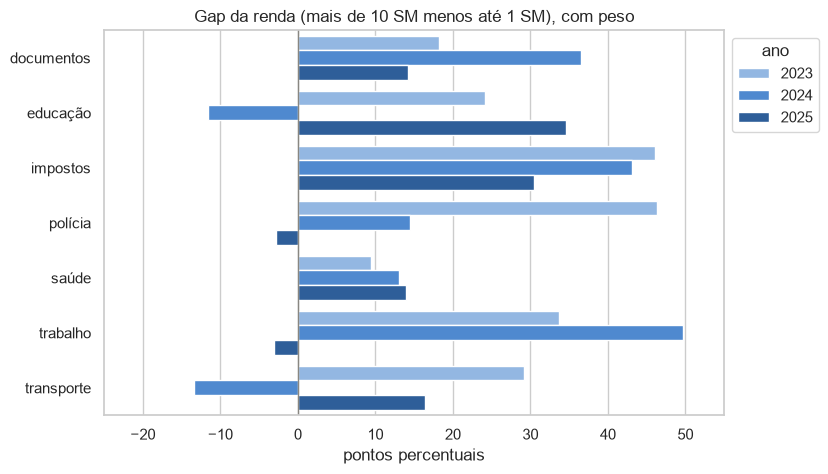

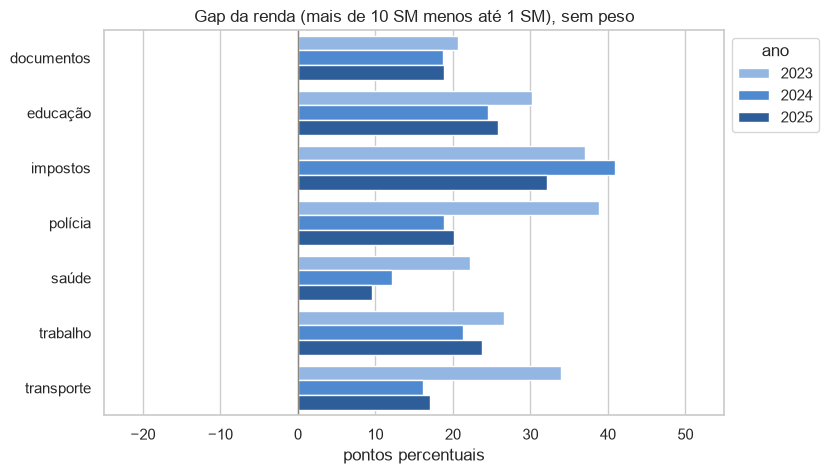

In [22]:
nomes_medida = {'pct_com_peso': 'com peso', 'pct_sem_peso': 'sem peso'}

for medida in ['pct_com_peso', 'pct_sem_peso']:
    pontas = gap_da_renda(tabelao, medida)

    plt.figure(figsize=(8, 5))                                   # tamanho da figura (largura, altura)
    sns.barplot(data=pontas, y='area', x='gap', hue='ano',       # uma barra por área (y) e ano (cor)
                palette=['#86b6ef', '#3987e5', '#1c5cab'],       # 3 tons de azul: claro = 2023, escuro = 2025
                errorbar=None)                                   # cada barra é um número só: sem barra de erro
    plt.axvline(0, color='#898781', linewidth=1)                 # linha do zero
    plt.xlim(-25, 55)                                            # escala fixa, igual nos dois gráficos
    plt.title(f'Gap da renda (mais de 10 SM menos até 1 SM), {nomes_medida[medida]}')
    plt.xlabel('pontos percentuais')
    plt.ylabel('')
    plt.legend(title='ano', loc='upper left', bbox_to_anchor=(1, 1))   # legenda do lado de fora

    # Salva a imagem em outputs/ (o nome do arquivo muda conforme a medida)
    plt.savefig(os.path.join(raiz_projeto, 'outputs', f'gap_renda_{medida}.png'), dpi=150, bbox_inches='tight')
    plt.show()

## 14. Salvar

- O tabelão vai pra `outputs/tabelao_eda.csv`. Os gráficos já foram salvos na seção 13.
- Como diz o `outputs/README.md`, os CSVs de `outputs/` saem com `sep=';'` e `decimal=','`, pro Power BI em português ler os números certo. O `encoding='utf-8-sig'` faz o Excel abrir os acentos (saúde, educação) sem bagunçar.
- Esses arquivos são exploratórios: **não têm margem de erro** e não são o resultado final do projeto.

In [23]:
caminho = os.path.join(raiz_projeto, 'outputs', 'tabelao_eda.csv')
tabelao.to_csv(caminho, sep=';', decimal=',', index=False, encoding='utf-8-sig')
print('Salvo:', os.path.relpath(caminho, raiz_projeto), '|', tabelao.shape[0], 'linhas x', tabelao.shape[1], 'colunas')

Salvo: outputs\tabelao_eda.csv | 462 linhas x 9 colunas


## 15. Resumo dos achados

1. **O universo importa.** O questionário aplicou o módulo G a umas mil pessoas por ano que ficam fora das tabelas oficiais (disseram "não" na C3 e "sim" na J3). Sem elas, os nossos % batem com os da CETIC. No % de cada área a mudança é pequena (no máximo 2,9 p.p., na polícia 2024), mas num grupo frágil pode ser grande (item 6).
2. **O peso muda o resultado.** Com peso, o % que resolveu pode mudar até ~10 p.p. em relação ao sem peso (transporte 2023: 32,8% sem peso e 43,2% com peso). Isso acontece porque poucas pessoas têm pesos enormes: entre quem respondeu transporte em 2023, a pessoa mais pesada sozinha tem 9,5% do peso.
3. **Grupos frágeis.** O n efetivo mostra quantas pessoas um grupo vale de verdade, considerando os pesos. "Não tem renda" em saúde 2024 tem 51 pessoas, mas vale cerca de 3, porque uma pessoa carrega 58% do peso do grupo. No tabelão, 66 das 462 linhas têm n efetivo menor que 10, principalmente analfabeto/infantil, indígena, não tem renda e mais de 10 SM.
4. **A regra "n ≥ 50" não basta.** 18 linhas passam nela, mas têm n efetivo menor que 10. Exemplo: transporte 2023, "1 a 2 SM", com 417 pessoas e n efetivo 9; o % pula de 29,3 para 49,6 quando entra o peso.
5. **A régua muda a resposta.** Em impostos 2024, a dimensão com a maior diferença é a renda quando o corte é n efetivo ≥ 10, e a região quando o corte é ≥ 20. Por isso, a regra para grupos pequenos tinha que ser decidida antes dos testes.
6. **Renda: a escada aparece.** Sem peso, a faixa mais rica resolve mais que a mais pobre em todas as áreas e anos (gap de 9,5 a 40,9 p.p.). Com peso, o gap balança e fica negativo em educação 2024, transporte 2024, polícia 2025 e trabalho 2025, sempre onde o "mais de 10 SM" tem n efetivo pequeno. A polícia 2024 era negativa antes do filtro do universo e deixou de ser: a pessoa que carregava 39% do peso do "até 1 SM" estava fora do universo. Impostos é a única área com gap grande e estável nas duas medidas (com peso: 46,1, 43,1 e 30,5 p.p.).
7. **Próximo passo.** O sem peso é estável, mas não representa o Brasil; o com peso representa, mas balança nas pontas frágeis. O notebook 03 vai dar uma margem de erro para cada %, e é ela que vai dizer quais diferenças são reais.

**O que foi decidido a partir destes achados (caderno de bordo, 12/10)**
- **Universo:** G1 e G2 só entre usuários de Internet de 16 anos ou mais, igual à CETIC (seção 2).
- **Faixas (decisão nº 2):** na análise, a renda fica em 5 faixas ("não tem renda" junto de "até 1 SM", e "5 a 10 SM" junto de "mais de 10 SM", formando "mais de 5 SM"), e a escolaridade em 3 (analfabeto/infantil junto do fundamental). O "não tem renda" tem n efetivo menor que 10 em 17 das 22 combinações de ano e área.
- **Grupos do gap (decisão nº 3):** sempre grupos fixos, nunca "maior menos menor": renda até 1 SM × mais de 5 SM, escolaridade até fundamental × superior, raça branca × preta e branca × parda, região Sudeste × cada uma das outras.
- **Grupos pequenos (decisão nº 4):** toda estimativa sai com IC e com aviso quando o CV passa de 30%. Nos testes, as categorias são fixas, e amarela e indígena aparecem à parte.

O tabelão daqui usa as faixas originais (7 de renda e 4 de escolaridade), porque é exploratório. As faixas novas entram no notebook 03.

Arquivos salvos em `outputs/`: `tabelao_eda.csv`, `gap_renda_pct_com_peso.png` e `gap_renda_pct_sem_peso.png`.